# Detección de fraude bancario con CRISP-DM

**Proyecto de ciencia de datos · 1 000 000 de transacciones (2020-2024)**

Este notebook recorre el ciclo completo de CRISP-DM: desde entender el negocio hasta dejar un modelo listo para usarse desde una app de Streamlit.

| Fase CRISP-DM | Dónde |
|---|---|
| 1. Comprensión del negocio | Sección 1 |
| 2. Comprensión de los datos | Sección 2 |
| 3. Preparación de los datos | Sección 3 |
| 4. Modelado | Sección 4 |
| 5. Evaluación | Sección 5 |
| 6. Despliegue | Sección 6 |

Dataset: [Bank Transaction Fraud Detection](https://www.kaggle.com/datasets/nafiulislam490/bank-transaction-fraud-detection-dataset) (Kaggle). Es un dataset **sintético**; lo tengo presente en cada conclusión.

## 1. Comprensión del negocio

**Situación.** Entre 2020 y 2024 el banco procesó 1 millón de transacciones y alrededor del **5.5 % fueron fraude**. Cada fraude no detectado es dinero perdido y un cliente molesto; cada alerta falsa cuesta tiempo de un analista y fricción para un cliente legítimo.

**Objetivos del proyecto**
1. Entender *qué* patrones distinguen una transacción fraudulenta de una legítima.
2. Construir un modelo que asigne a cada transacción una **probabilidad de fraude**, tanto para el histórico como para las transacciones **nuevas** que lleguen.
3. Dejarlo desplegado en una app donde un analista pueda puntuar una transacción o un lote completo.

**Criterios de éxito (definidos antes de modelar)**

- *Técnico:* superar claramente al azar en **PR-AUC** (el azar equivale a la tasa de fraude, ≈ 0.055) y en ROC-AUC (azar = 0.5), medido **fuera del tiempo de entrenamiento**.
- *Operativo:* poder decir "si el equipo revisa el X % de transacciones con mayor riesgo, captura Y % de los fraudes". Ese es el lenguaje que usa un área de riesgo.
- *Confianza:* probabilidades **calibradas** (si el modelo dice 20 %, que ~20 % de esas transacciones sean fraude).

**Cómo voy a evaluar (y por qué)**

- **No uso accuracy.** Un modelo que diga siempre "no es fraude" acierta 94.5 % y no sirve para nada.
- **Partición temporal**, no aleatoria: entreno con el pasado y pruebo con el futuro, igual que en producción. Entreno 2020-2022, valido 2023 y dejo **2024 intacto** para la evaluación final.
- Métricas: PR-AUC, ROC-AUC, Brier / log-loss (calibración), y precisión / recall / lift en un punto de operación.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))          # para importar src/
from src.features import (FEATURES, FEATURE_LABELS, MERCHANT_CATEGORIES, NIGHT_HOURS,
                          RISKY_MERCHANTS, build_features)

SEED = 42
np.random.seed(SEED)

# --- Estilo de gráficos: un acento (azul), un segundo color (naranja) y grises -----
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b9b8b1"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e8e7e2", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
})
PCT0 = mtick.PercentFormatter(1.0, decimals=0)
PCT1 = mtick.PercentFormatter(1.0, decimals=1)

FIG_DIR = Path("../reports/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = Path("../models"); MODEL_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("../data"); DATA_DIR.mkdir(exist_ok=True)

def save_show(name):
    plt.savefig(FIG_DIR / name, bbox_inches="tight")
    plt.show()

## 2. Comprensión de los datos

Cargo el CSV. Un detalle importante: `fraud_type` trae el texto `"None"` para las transacciones legítimas, y pandas lo interpreta como **nulo** por defecto. Al leer con `keep_default_na=False` conservo ese texto como una categoría más y evito confundirlo con datos faltantes reales.

In [2]:
CANDIDATOS = [Path(os.environ.get("FRAUD_DATA", "__no__")), Path("../data/bank_fraud.csv"),
              Path("data/bank_fraud.csv"),
              Path("/kaggle/input/bank-transaction-fraud-detection-dataset/bank_fraud.csv")]
DATA_PATH = next((p for p in CANDIDATOS if p.is_file()), None)
assert DATA_PATH is not None, "Descarga bank_fraud.csv de Kaggle y colócalo en la carpeta data/"

df = pd.read_csv(DATA_PATH, keep_default_na=False)
df["fecha_hora"] = pd.to_datetime(df["transaction_date"] + " " + df["transaction_time"])
df = df.sort_values("fecha_hora").reset_index(drop=True)
df["anio"] = df["fecha_hora"].dt.year
BASE_RATE = df["is_fraud"].mean()

print(f"Filas: {len(df):,}  |  Columnas: {df.shape[1] - 2}  |  Periodo: {df.fecha_hora.min():%Y-%m-%d} a {df.fecha_hora.max():%Y-%m-%d}")
print(f"Tasa de fraude: {BASE_RATE:.2%}  ({df.is_fraud.sum():,} fraudes)")
df.drop(columns=["fecha_hora", "anio"]).head(5)

Filas: 1,000,000  |  Columnas: 26  |  Periodo: 2020-01-01 a 2024-12-30
Tasa de fraude: 5.53%  (55,255 fraudes)


,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,...,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000525331,CUST00124140,2020-01-01,00:00:00,0,0,1,USA,Delhi,Clothing,...,19.87,154,22,42.3,1.13,0,0,0,0,None
1,TXN0000214279,CUST00127218,2020-01-01,00:00:00,0,0,1,Australia,New York,Clothing,...,32.44,161,22,4.9,4.42,0,2,1,0,None
2,TXN0000483733,CUST00118277,2020-01-01,00:02:00,0,0,1,UK,Manchester,Entertainment,...,121.45,163,24,48.6,5.17,0,0,0,0,None
3,TXN0000044764,CUST00115057,2020-01-01,00:13:00,0,0,1,Mexico,Rio,Education,...,81.49,162,19,0.8,4.28,0,0,0,0,None
4,TXN0000691609,CUST00150856,2020-01-01,00:13:00,0,0,1,Mexico,New York,Utilities,...,118.67,152,26,8.5,2.12,0,3,0,0,None


### 2.1 Calidad de los datos

In [3]:
checks = {
    "Valores nulos (reales)": int(df.drop(columns=["fecha_hora"]).isna().sum().sum()),
    "transaction_id duplicados": int(df.transaction_id.duplicated().sum()),
    "Montos <= 0": int((df.transaction_amount <= 0).sum()),
    "is_night_transaction coherente con la hora": f"{(df.is_night_transaction == df.hour_of_day.isin(NIGHT_HOURS).astype(int)).mean():.2%}",
    "is_weekend coherente con la fecha": f"{(df.is_weekend == (df.fecha_hora.dt.dayofweek >= 5).astype(int)).mean():.2%}",
    "hour_of_day coherente con transaction_time": f"{(df.hour_of_day == df.fecha_hora.dt.hour).mean():.2%}",
}
# ¿La ciudad "pertenece" al país? Si fuera real, cada ciudad estaría concentrada en un país.
pureza_ciudad = pd.crosstab(df.city, df.country, normalize="index").max(axis=1).mean()
checks["Pureza ciudad -> país (1.0 = cada ciudad en un solo país)"] = f"{pureza_ciudad:.2f}"
pd.Series(checks, name="resultado").to_frame()

,resultado
Valores nulos (reales),0
transaction_id duplicados,0
Montos <= 0,0
is_night_transaction coherente con la hora,100.00%
is_weekend coherente con la fecha,100.00%
hour_of_day coherente con transaction_time,100.00%
Pureza ciudad -> país (1.0 = cada ciudad en un solo país),0.30


**Lo que encuentro**

- No hay nulos reales ni IDs duplicados, y las banderas derivadas (`is_night_transaction`, `is_weekend`, `hour_of_day`) son 100 % coherentes. Eso me deja confiar en ellas.
- La **ciudad no corresponde al país** (hay clientes de USA comprando en Londres o Tokio con la misma probabilidad que en casa). En un banco real eso sería una señal fuerte; aquí es evidencia de que el dataset es **sintético**. Lo tendré en cuenta al interpretar: no voy a vender como "hallazgo de negocio" algo que es una propiedad del generador de datos.
- `fraud_type` solo existe cuando hay fraude, así que es **fuga de información (leakage)**: si lo uso como variable, el modelo "descubriría" el fraude mirando la respuesta. Lo excluyo del entrenamiento y lo reservo para analizar errores.

### 2.2 Variable objetivo y estabilidad en el tiempo

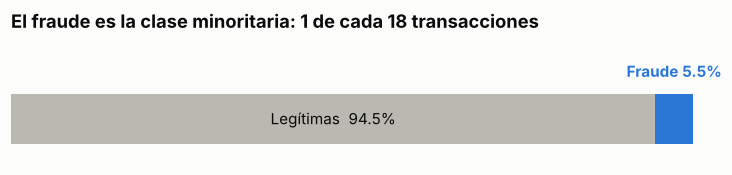

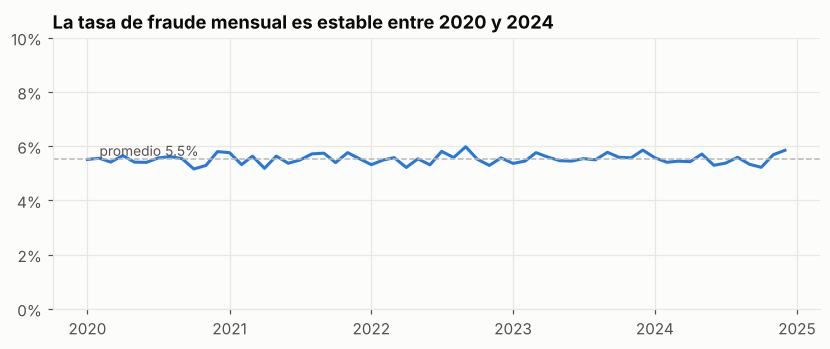

In [4]:
fig, ax = plt.subplots(figsize=(8, 1.5))
ax.barh([0], [1 - BASE_RATE], color=GRAY, height=0.55)
ax.barh([0], [BASE_RATE], left=[1 - BASE_RATE], color=BLUE, height=0.55)
ax.text((1 - BASE_RATE) / 2, 0, f"Legítimas  {1 - BASE_RATE:.1%}", ha="center", va="center", color=INK)
ax.text(1 - BASE_RATE / 2, 0.42, f"Fraude {BASE_RATE:.1%}", ha="center", va="bottom", color=BLUE, fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(-0.5, 0.9); ax.axis("off")
ax.set_title("El fraude es la clase minoritaria: 1 de cada 18 transacciones")
save_show("01_balance_clases.png")

mensual = df.set_index("fecha_hora").is_fraud.resample("MS").mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(mensual.index, mensual.values, color=BLUE, lw=2)
ax.axhline(BASE_RATE, color=GRAY, ls="--", lw=1)
ax.text(mensual.index[1], BASE_RATE + 0.0012, f"promedio {BASE_RATE:.1%}", color=INK2, fontsize=9)
ax.set_ylim(0, 0.10); ax.yaxis.set_major_formatter(PCT0)
ax.set_title("La tasa de fraude mensual es estable entre 2020 y 2024")
save_show("02_fraude_mensual.png")

La tasa se mantiene plana durante los 5 años: **no hay deriva ni estacionalidad** que explotar. Por eso la partición temporal no es para "predecir una tendencia", sino para comprobar que lo aprendido en el pasado se sostiene en el futuro.

Aclaración sobre el pedido original de "estimar futuras transacciones": un modelo de clasificación no predice *cuántas* transacciones vendrán, sino que **puntúa cada transacción nueva** cuando llega. Esa es la parte que despliego en la app.

### 2.3 ¿Qué variables separan fraude de no fraude?

In [5]:
from scipy.stats import chi2_contingency

def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return float(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))))

cats = ["merchant_category", "payment_method", "device_type", "country", "city"]
resumen_cat = pd.DataFrame({
    "categorías": [df[c].nunique() for c in cats],
    "tasa mín": [df.groupby(c).is_fraud.mean().min() for c in cats],
    "tasa máx": [df.groupby(c).is_fraud.mean().max() for c in cats],
    "V de Cramér": [cramers_v(df[c], df.is_fraud) for c in cats],
}, index=cats).sort_values("V de Cramér", ascending=False)
resumen_cat.style.format({"tasa mín": "{:.2%}", "tasa máx": "{:.2%}", "V de Cramér": "{:.3f}"})

,categorías,tasa mín,tasa máx,V de Cramér
merchant_category,15,4.62%,8.74%,0.069
city,20,5.37%,5.63%,0.003
payment_method,6,5.46%,5.67%,0.003
device_type,5,5.44%,5.61%,0.003
country,10,5.42%,5.67%,0.002


Con 1 millón de filas **cualquier diferencia sale "estadísticamente significativa"**, por eso miro el tamaño del efecto (V de Cramér) y no el p-valor. Solo `merchant_category` tiene un efecto apreciable; `payment_method`, `device_type`, `country` y `city` varían menos de un punto porcentual alrededor de la media (≈ 0 de V de Cramér). Esto contradice una intuición que se puede sacar del conteo bruto: que "Mobile" o "Credit Card" concentran más fraude simplemente porque concentran más transacciones. **Su tasa de fraude es la misma que la del resto.**

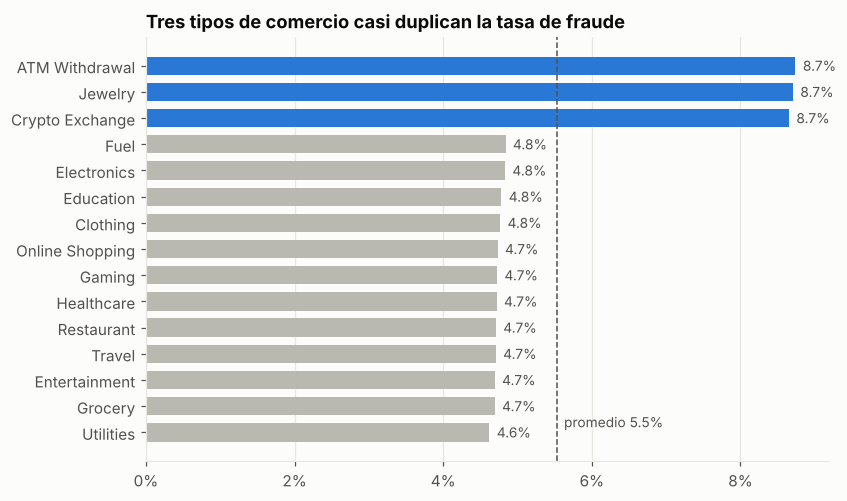

In [6]:
tasa_mcc = df.groupby("merchant_category").is_fraud.mean().sort_values()
colores = [BLUE if m in RISKY_MERCHANTS else GRAY for m in tasa_mcc.index]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(tasa_mcc.index, tasa_mcc.values, color=colores, height=0.7)
ax.axvline(BASE_RATE, color=INK2, ls="--", lw=1)
ax.text(BASE_RATE + 0.001, 0.2, f"promedio {BASE_RATE:.1%}", color=INK2, fontsize=9)
for y, v in enumerate(tasa_mcc.values):
    ax.text(v + 0.001, y, f"{v:.1%}", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(PCT0); ax.grid(axis="y", visible=False)
ax.set_title("Tres tipos de comercio casi duplican la tasa de fraude")
save_show("03_fraude_por_comercio.png")

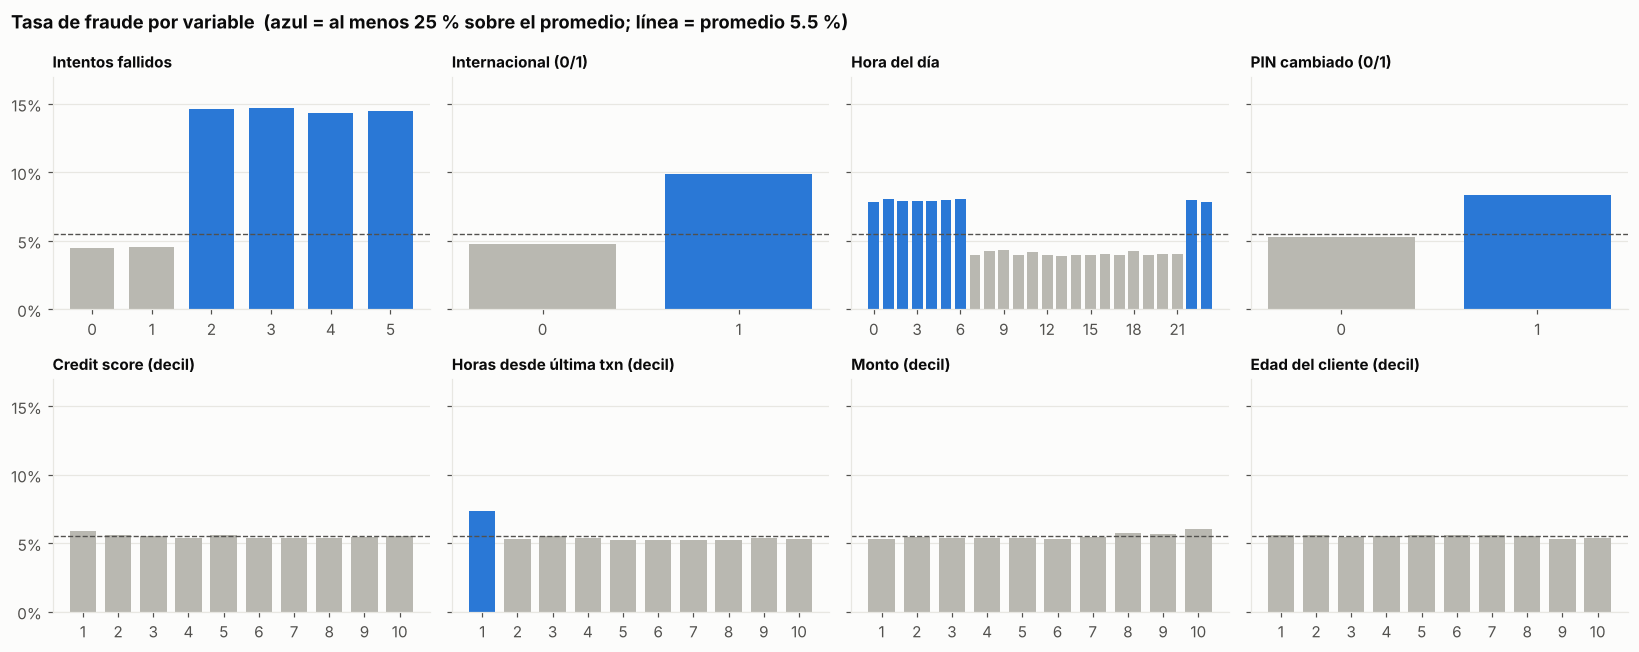

In [7]:
# Tasa de fraude por tramo de cada variable numérica (deciles) o por valor (si son discretas).
def tasa_por(col, discreta=False):
    if discreta:
        return df.groupby(col).is_fraud.mean()
    tramos = pd.qcut(df[col], 10, duplicates="drop")
    t = df.groupby(tramos, observed=True).is_fraud.mean()
    t.index = range(1, len(t) + 1)
    return t

paneles = [("failed_attempts", True, "Intentos fallidos"), ("is_international", True, "Internacional (0/1)"),
           ("hour_of_day", True, "Hora del día"), ("pin_changed_recently", True, "PIN cambiado (0/1)"),
           ("credit_score", False, "Credit score (decil)"), ("time_since_last_txn_hrs", False, "Horas desde última txn (decil)"),
           ("transaction_amount", False, "Monto (decil)"), ("customer_age", False, "Edad del cliente (decil)")]

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharey=True)
for ax, (col, disc, titulo) in zip(axes.ravel(), paneles):
    t = tasa_por(col, disc)
    ax.bar(t.index.astype(str), t.values, color=[BLUE if v >= 1.25 * BASE_RATE else GRAY for v in t.values], width=0.75)
    ax.axhline(BASE_RATE, color=INK2, ls="--", lw=0.9)
    ax.set_title(titulo, fontsize=10); ax.yaxis.set_major_formatter(PCT0); ax.grid(axis="x", visible=False)
    if col == "hour_of_day":
        ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(range(0, 24, 3))
axes[0, 0].set_ylim(0, 0.17); axes[0, 0].set_yticks([0, 0.05, 0.10, 0.15])
fig.suptitle("Tasa de fraude por variable  (azul = al menos 25 % sobre el promedio; línea = promedio 5.5 %)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_show("04_fraude_por_variable.png")

Cinco señales claras, todas con una lógica de negocio razonable:

1. **Intentos fallidos ≥ 2** → la tasa se triplica (4.5 % → ~14.5 %). Con 0 o 1 intento no hay diferencia; con 2 o más, el efecto ya no crece. Es un *umbral*, no una relación lineal.
2. **Transacción internacional** → ~9.9 % vs ~4.8 %.
3. **Franja nocturna** (22:00-06:59) → ~8 % vs ~4 %; dentro de cada franja la hora exacta no importa.
4. **Comercio de riesgo** (cripto, joyería, cajero) → ~8.7 % vs ~4.7 %.
5. **PIN cambiado recientemente** → ~8.4 % vs ~5.3 %.

Hay además efectos pequeños pero reales en los extremos: transacciones hechas **menos de ~1 hora** después de la anterior, montos del decil más alto y credit score muy bajo. En cambio la **edad del cliente** (último panel) no aporta nada, y es el tipo de variable que un análisis sin control habría "justificado" por intuición.

In [8]:
from sklearn.metrics import roc_auc_score

numericas = df.select_dtypes("number").columns.drop(["is_fraud", "anio"])
auc_uni = pd.Series({c: roc_auc_score(df.is_fraud, df[c]) for c in numericas})
poder = (auc_uni - 0.5).abs().add(0.5).sort_values(ascending=False)   # sin importar el signo
poder.rename("ROC-AUC univariado").to_frame().head(10).style.format("{:.3f}")

,ROC-AUC univariado
is_night_transaction,0.587
failed_attempts,0.587
is_international,0.562
hour_of_day,0.549
pin_changed_recently,0.522
time_since_last_txn_hrs,0.520
transaction_amount,0.510
credit_score,0.505
customer_age,0.504
account_balance,0.503


Mismo mensaje por otra vía: el poder discriminante de cada variable por sí sola es modesto (ninguna pasa de ~0.60). La señal está en la **combinación** de varias banderas de riesgo. Lo compruebo contando cuántas se activan a la vez:

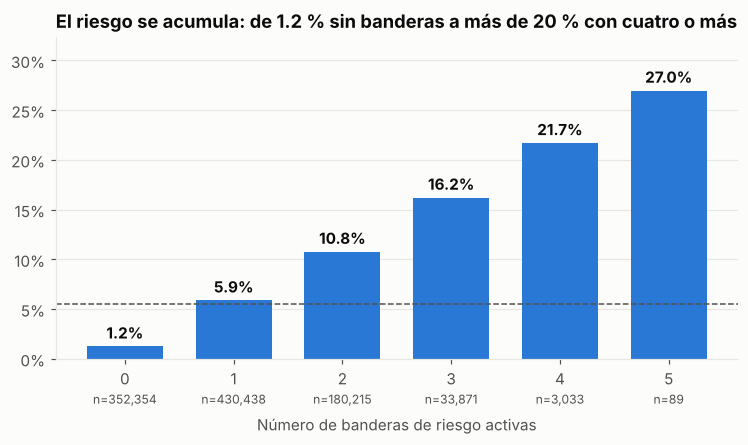

ROC-AUC de la regla 'contar banderas' (sin ningún modelo): 0.701


In [9]:
banderas = pd.DataFrame({
    "intentos_fallidos_2+": df.failed_attempts >= 2,
    "internacional": df.is_international == 1,
    "nocturna": df.is_night_transaction == 1,
    "comercio_riesgo": df.merchant_category.isin(RISKY_MERCHANTS),
    "pin_cambiado": df.pin_changed_recently == 1,
}).astype(int)
df["n_banderas"] = banderas.sum(axis=1)
t = df.groupby("n_banderas").is_fraud.agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(t.index.astype(str), t["mean"], color=BLUE, width=0.7)
for x, (m, n) in enumerate(zip(t["mean"], t["size"])):
    ax.text(x, m + 0.008, f"{m:.1%}", ha="center", fontsize=10, fontweight="bold")
    ax.text(x, -0.045, f"n={n:,}", ha="center", fontsize=8, color=INK2)
ax.axhline(BASE_RATE, color=INK2, ls="--", lw=1)
ax.set_ylim(0, t["mean"].max() * 1.2); ax.yaxis.set_major_formatter(PCT0); ax.grid(axis="x", visible=False)
ax.set_xlabel("Número de banderas de riesgo activas", labelpad=18)
ax.set_title("El riesgo se acumula: de 1.2 % sin banderas a más de 20 % con cuatro o más")
save_show("05_acumulacion_banderas.png")
auc_regla = roc_auc_score(df.is_fraud, df.n_banderas)
print(f"ROC-AUC de la regla 'contar banderas' (sin ningún modelo): {auc_regla:.3f}")

Una regla de negocio que simplemente **cuenta banderas** ya separa muy bien los grupos extremos. Esto me sirve de referencia honesta: el modelo tiene que superar a esta regla para justificar su complejidad. También anticipa algo: si la señal viene de pocas banderas aditivas, el techo de rendimiento no será alto.

### 2.4 Hipótesis que probé y descarté

¿El **historial del cliente** ayuda? Para cada transacción conté cuántos fraudes previos tenía ese cliente (solo mirando hacia atrás en el tiempo).

In [10]:
g = df.groupby("customer_id").is_fraud
df["fraudes_previos"] = (g.cumsum() - df.is_fraud).clip(upper=2)
df["txns_previas_cliente"] = g.cumcount()
hist = df[df.txns_previas_cliente > 0].groupby("fraudes_previos").is_fraud.agg(["mean", "size"])
hist.index = hist.index.map({0: "0 fraudes previos", 1: "1 fraude previo", 2: "2+ fraudes previos"})
print(f"Clientes únicos: {df.customer_id.nunique():,}  (≈ {len(df)/df.customer_id.nunique():.1f} transacciones por cliente)")
hist.style.format({"mean": "{:.2%}", "size": "{:,}"})

Clientes únicos: 198,662  (≈ 5.0 transacciones por cliente)


,mean,size
fraudes_previos,,
0 fraudes previos,5.51%,"675,291"
1 fraude previo,5.69%,"114,574"
2+ fraudes previos,5.40%,"11,473"


Tener fraudes previos no cambia la probabilidad (5.5 % vs 5.7 % vs 5.4 %): **cada transacción es independiente del cliente**. Descarto el historial como variable. En datos reales sería de las primeras ideas a probar, y vale la pena dejar constancia de que se probó.

## 3. Preparación de los datos

**Qué dejo fuera y por qué**

| Variable(s) | Decisión | Motivo |
|---|---|---|
| `transaction_id`, `customer_id` | Excluir | Identificadores sin poder predictivo (el historial por cliente ya se descartó). |
| `transaction_date`, `transaction_time` | Usar solo para ordenar y particionar | Sin deriva ni estacionalidad; la hora ya está en `hour_of_day`. |
| `fraud_type` | Excluir | **Leakage**: solo existe si hubo fraude. |
| `city`, `country`, `payment_method`, `device_type` | Excluir | Tasa de fraude idéntica entre categorías (V de Cramér ≈ 0). Menos variables = modelo más simple, estable y fácil de operar. |
| `customer_age`, `distance_from_home_km`, `account_age_years`, `num_prev_transactions`, `transaction_freq_monthly`, `is_weekend` | Excluir | Sin relación con el fraude en el EDA. |

Más abajo (sección 4.4) **compruebo con datos** que esta selección no pierde rendimiento frente a usar las 20 variables disponibles.

**Transformaciones** (en `src/features.py`, compartidas con la app para evitar discrepancias entre entrenamiento y producción):
- `log1p` en monto y saldo (asimetría de ~10 y ~6).
- `amount_to_balance`: qué proporción del saldo representa la compra.
- `is_night` derivada de la hora.
- `merchant_category` como categoría nativa de LightGBM (sin one-hot).

**Outliers:** no los elimino. Los montos muy altos son parte del negocio (y el decil superior de monto tiene *más* fraude); los modelos de árboles son robustos a ellos.

In [11]:
TRAIN_HASTA, VALID_ANIO, TEST_ANIO = 2022, 2023, 2024
es_train = df.anio <= TRAIN_HASTA
es_valid = df.anio == VALID_ANIO
es_test = df.anio == TEST_ANIO

X_all = build_features(df)
y = df["is_fraud"]
X_tr, y_tr = X_all[es_train], y[es_train]
X_va, y_va = X_all[es_valid], y[es_valid]
X_te, y_te = X_all[es_test], y[es_test]

pd.DataFrame({
    "periodo": ["2020-2022", "2023", "2024"],
    "uso": ["Entrenamiento", "Validación (elegir modelo)", "Prueba final (intocable)"],
    "filas": [len(X_tr), len(X_va), len(X_te)],
    "fraudes": [y_tr.sum(), y_va.sum(), y_te.sum()],
    "tasa de fraude": [y_tr.mean(), y_va.mean(), y_te.mean()],
}).style.format({"filas": "{:,}", "fraudes": "{:,}", "tasa de fraude": "{:.2%}"}).hide(axis="index")

periodo,uso,filas,fraudes,tasa de fraude
2020-2022,Entrenamiento,"601,002","33,169",5.52%
2023,Validación (elegir modelo),"199,673","11,137",5.58%
2024,Prueba final (intocable),"199,325","10,949",5.49%


In [12]:
print("Variables del modelo:", FEATURES)
X_tr.describe().T[["mean", "min", "max"]].round(2)

Variables del modelo: ['merchant_category', 'hour_of_day', 'is_night', 'failed_attempts', 'is_international', 'pin_changed_recently', 'log_amount', 'amount_to_balance', 'log_account_balance', 'credit_score', 'time_since_last_txn_hrs']


,mean,min,max
hour_of_day,11.50,0.00,23.00
is_night,0.37,0.00,1.00
failed_attempts,0.38,0.00,5.00
is_international,0.15,0.00,1.00
pin_changed_recently,0.08,0.00,1.00
log_amount,4.42,0.69,10.74
amount_to_balance,0.05,0.00,31.39
log_account_balance,9.00,4.62,13.12
credit_score,678.99,300.00,850.00
time_since_last_txn_hrs,12.00,0.00,140.46


## 4. Modelado

### 4.1 Líneas base: lo mínimo que el modelo debe superar

1. **Azar / tasa base**: PR-AUC = 0.055, ROC-AUC = 0.50.
2. **Regla de banderas** (sección 2): contar señales de riesgo.
3. **Regresión logística**: el modelo lineal clásico e interpretable.

In [13]:
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def evaluar(y_true, p):
    p = np.asarray(p, float)
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "Brier": brier_score_loss(y_true, p) if p.max() <= 1 else np.nan,
            "LogLoss": log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6)) if p.max() <= 1 else np.nan}

COLS_NUM = [c for c in FEATURES if c != "merchant_category"]

def pipeline_lineal():
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["merchant_category"]),
                             ("num", StandardScaler(), COLS_NUM)])
    return make_pipeline(pre, LogisticRegression(max_iter=1000))

def n_banderas(X):
    return ((X.failed_attempts >= 2).astype(int) + X.is_international + X.is_night + X.pin_changed_recently
            + X.merchant_category.isin(RISKY_MERCHANTS).astype(int))

resultados_val = {}
resultados_val["Azar (tasa base)"] = evaluar(y_va, np.full(len(y_va), y_tr.mean()))
resultados_val["Regla de banderas"] = evaluar(y_va, n_banderas(X_va) / 5)
t0 = time.time(); lr = pipeline_lineal().fit(X_tr, y_tr)
resultados_val["Regresión logística"] = evaluar(y_va, lr.predict_proba(X_va)[:, 1])
tiempos = {"Regresión logística": time.time() - t0}
pd.DataFrame(resultados_val).T.style.format("{:.4f}")

,ROC-AUC,PR-AUC,Brier,LogLoss
Azar (tasa base),0.5000,0.0558,0.0527,0.2152
Regla de banderas,0.6976,0.1006,0.0827,0.3269
Regresión logística,0.7113,0.1191,0.0513,0.2013


### 4.2 Comparación de algoritmos

Pruebo tres familias de modelos no lineales con los mismos datos de entrenamiento y los comparo en la **validación (2023)**. Los de boosting usan *early stopping* sobre la validación para no sobreajustar.

In [14]:
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier

# --- Random Forest ---
t0 = time.time()
pre_rf = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), ["merchant_category"]),
                            ("num", "passthrough", COLS_NUM)])
rf = make_pipeline(pre_rf, RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=200,
                                                  max_samples=0.4, n_jobs=2, random_state=SEED))
rf.fit(X_tr, y_tr)
resultados_val["Random Forest"] = evaluar(y_va, rf.predict_proba(X_va)[:, 1]); tiempos["Random Forest"] = time.time() - t0

# --- XGBoost ---
t0 = time.time()
xgbm = xgb.XGBClassifier(n_estimators=800, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         min_child_weight=50, reg_lambda=5, tree_method="hist", enable_categorical=True,
                         eval_metric="logloss", early_stopping_rounds=50, n_jobs=2, random_state=SEED)
xgbm.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
resultados_val["XGBoost"] = evaluar(y_va, xgbm.predict_proba(X_va)[:, 1]); tiempos["XGBoost"] = time.time() - t0

# --- LightGBM ---
PARAMS_BASE = dict(n_estimators=1500, learning_rate=0.05, num_leaves=15, min_child_samples=200, subsample=0.8,
                   subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, random_state=SEED, n_jobs=2, verbose=-1)
def fit_lgbm(Xa, ya, Xb, yb, **extra):
    m = lgb.LGBMClassifier(**{**PARAMS_BASE, **extra})
    m.fit(Xa, ya, eval_set=[(Xb, yb)], callbacks=[lgb.early_stopping(50, verbose=False)])
    return m

t0 = time.time()
lgbm = fit_lgbm(X_tr, y_tr, X_va, y_va)
resultados_val["LightGBM"] = evaluar(y_va, lgbm.predict_proba(X_va)[:, 1]); tiempos["LightGBM"] = time.time() - t0

tabla = pd.DataFrame(resultados_val).T
tabla["Tiempo (s)"] = pd.Series(tiempos)
tabla.style.format({"ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Brier": "{:.4f}", "LogLoss": "{:.4f}", "Tiempo (s)": "{:.0f}"}, na_rep="—")

,ROC-AUC,PR-AUC,Brier,LogLoss,Tiempo (s)
Azar (tasa base),0.5000,0.0558,0.0527,0.2152,—
Regla de banderas,0.6976,0.1006,0.0827,0.3269,—
Regresión logística,0.7113,0.1191,0.0513,0.2013,1
Random Forest,0.7231,0.1261,0.0508,0.1977,44
XGBoost,0.7234,0.1262,0.0507,0.1973,10
LightGBM,0.7236,0.1270,0.0507,0.1970,7


Los modelos de boosting y el Random Forest quedan muy cerca entre sí y por encima de la regresión logística. La diferencia entre algoritmos es pequeña comparada con la diferencia entre "modelo" y "azar". **LightGBM** es el candidato: mejor o igual en PR-AUC, entrena rápido y su archivo es liviano (importante para desplegar gratis).

### 4.3 ¿Hay que balancear las clases?

En mi avance anterior probé submuestreo, sobremuestreo y SMOTE-NC con regresión logística. Aquí hago la comparación con el mejor modelo, mismos datos y misma semilla, para decidir con evidencia:

In [15]:
rng = np.random.default_rng(SEED)
idx_pos = np.flatnonzero(y_tr.values == 1); idx_neg = np.flatnonzero(y_tr.values == 0)
idx_sub = np.sort(np.concatenate([idx_pos, rng.choice(idx_neg, size=len(idx_pos), replace=False)]))
peso = (y_tr == 0).sum() / (y_tr == 1).sum()

exp = {}
m_a = fit_lgbm(X_tr, y_tr, X_va, y_va)                                              ; exp["Sin balancear (distribución real)"] = m_a
m_b = fit_lgbm(X_tr, y_tr, X_va, y_va, scale_pos_weight=peso)                       ; exp["Con pesos de clase"] = m_b
m_c = fit_lgbm(X_tr.iloc[idx_sub], y_tr.iloc[idx_sub], X_va, y_va)                  ; exp["Submuestreo 1:1"] = m_c
pd.DataFrame({k: evaluar(y_va, m.predict_proba(X_va)[:, 1]) for k, m in exp.items()}).T \
  .style.format("{:.4f}")

,ROC-AUC,PR-AUC,Brier,LogLoss
Sin balancear (distribución real),0.7236,0.1270,0.0507,0.1970
Con pesos de clase,0.7171,0.1160,0.0522,0.2122
Submuestreo 1:1,0.7230,0.1262,0.2149,0.6080


**Conclusión:** el balanceo **no mejora la capacidad de ordenar** (con pesos de clase incluso empeora: PR-AUC 0.116 frente a 0.127; el submuestreo queda igual) y **destruye la calibración** (Brier 0.215 frente a 0.051 con submuestreo: el modelo "cree" que el fraude es mucho más frecuente de lo que es). Como quiero probabilidades confiables para decidir umbrales y estimar costos, **entreno con la distribución real**. Descarto también SMOTE-NC: con 600 000 filas mixtas es lento y no hay evidencia de que aporte donde ni siquiera el balanceo simple lo hace.

### 4.4 Selección de variables: ¿20 o 11?

Contrasto mi selección del EDA contra darle al modelo **todas** las variables del dataset (incluidas ciudad, país, método de pago, dispositivo, edad, etc.):

In [16]:
ids_y_fugas = ["transaction_id", "customer_id", "transaction_date", "transaction_time", "fraud_type",
               "is_fraud", "fecha_hora", "anio", "n_banderas", "fraudes_previos", "txns_previas_cliente"]
X_full = df.drop(columns=ids_y_fugas).copy()
for c in ["merchant_category", "country", "city", "payment_method", "device_type"]:
    X_full[c] = X_full[c].astype("category")

m_full = fit_lgbm(X_full[es_train], y_tr, X_full[es_valid], y_va)
p_full = m_full.predict_proba(X_full[es_valid])[:, 1]
p_sel = exp["Sin balancear (distribución real)"].predict_proba(X_va)[:, 1]
comp = pd.DataFrame({f"Todas ({X_full.shape[1]} variables)": evaluar(y_va, p_full),
                     f"Seleccionadas ({len(FEATURES)} variables)": evaluar(y_va, p_sel)}).T
comp.style.format("{:.4f}")

,ROC-AUC,PR-AUC,Brier,LogLoss
Todas (20 variables),0.7233,0.1268,0.0507,0.1971
Seleccionadas (11 variables),0.7236,0.1270,0.0507,0.1970


Las 11 variables seleccionadas rinden **igual** que las 20 (la diferencia está en el cuarto decimal). Quedarme con el set corto me da un modelo más simple, más estable y una app que pide 9 datos en vez de 20.

### 4.5 Ajuste de hiperparámetros

Búsqueda aleatoria de 10 configuraciones de LightGBM, evaluadas siempre en la validación 2023 (nunca en la prueba).

In [17]:
import itertools
espacio = dict(num_leaves=[7, 15, 31, 63], min_child_samples=[50, 200, 1000], colsample_bytree=[0.6, 0.8, 1.0],
               reg_lambda=[0, 5, 20], learning_rate=[0.03, 0.05, 0.1])
rng = np.random.default_rng(SEED)
combos = list(itertools.product(*espacio.values()))
elegidas = [dict(zip(espacio, combos[i])) for i in rng.choice(len(combos), size=10, replace=False)]

filas, modelos_cv = [], []
for cfg in elegidas:
    t0 = time.time()
    m = fit_lgbm(X_tr, y_tr, X_va, y_va, **cfg)
    ev = evaluar(y_va, m.predict_proba(X_va)[:, 1])
    filas.append({**cfg, "árboles": m.best_iteration_, "PR-AUC val": ev["PR-AUC"], "ROC-AUC val": ev["ROC-AUC"], "LogLoss val": ev["LogLoss"], "s": time.time() - t0})
    modelos_cv.append(m)
busqueda = pd.DataFrame(filas).sort_values("PR-AUC val", ascending=False).reset_index(drop=True)
MEJOR_CFG = {k: (int(v) if k in ("num_leaves", "min_child_samples") else float(v)) for k, v in busqueda.iloc[0][list(espacio)].items()}
MEJOR_N = int(busqueda.iloc[0]["árboles"])
print("Mejor configuración:", MEJOR_CFG, "| árboles:", MEJOR_N)
busqueda.head(5).style.format({"PR-AUC val": "{:.4f}", "ROC-AUC val": "{:.4f}", "LogLoss val": "{:.4f}", "s": "{:.0f}"})

Mejor configuración: {'num_leaves': 7, 'min_child_samples': 200, 'colsample_bytree': 0.6, 'reg_lambda': 0.0, 'learning_rate': 0.05} | árboles: 162


,num_leaves,min_child_samples,colsample_bytree,reg_lambda,learning_rate,árboles,PR-AUC val,ROC-AUC val,LogLoss val,s
0,7,200,0.600000,0,0.050000,162,0.1277,0.7242,0.1970,8
1,7,200,0.600000,0,0.030000,301,0.1275,0.7239,0.1970,13
2,7,200,0.600000,5,0.030000,324,0.1274,0.7240,0.1970,15
3,7,1000,0.800000,0,0.100000,69,0.1274,0.7240,0.1970,5
4,15,1000,0.600000,5,0.030000,225,0.1264,0.7235,0.1972,14


Las configuraciones top rinden casi igual (diferencias en el cuarto decimal): el modelo es **estable** ante los hiperparámetros, otra señal de que la señal disponible está bien capturada y no hay mucho más que exprimir con tuning.

## 5. Evaluación (sobre 2024, datos que el modelo nunca vio)

Reentreno el modelo ganador con **2020-2023** (entrenamiento + validación) usando el número de árboles que eligió el early stopping, y lo evalúo **una sola vez** en 2024. Para que la comparación sea justa, la regresión logística se reentrena con los mismos datos.

In [18]:
es_fit = es_train | es_valid
final_params = {**PARAMS_BASE, **MEJOR_CFG, "n_estimators": MEJOR_N}
final = lgb.LGBMClassifier(**final_params).fit(X_all[es_fit], y[es_fit])
lr_final = pipeline_lineal().fit(X_all[es_fit], y[es_fit])

p_te = final.predict_proba(X_te)[:, 1]
p_lr = lr_final.predict_proba(X_te)[:, 1]
score_reglas = n_banderas(X_te).values / 5

res_test = pd.DataFrame({
    "Azar": evaluar(y_te, np.full(len(y_te), y[es_fit].mean())),
    "Regla de banderas": evaluar(y_te, score_reglas),
    "Regresión logística": evaluar(y_te, p_lr),
    "LightGBM (final)": evaluar(y_te, p_te),
}).T
res_test.style.format("{:.4f}", na_rep="—")

,ROC-AUC,PR-AUC,Brier,LogLoss
Azar,0.5000,0.0549,0.0519,0.2128
Regla de banderas,0.7040,0.1009,0.0820,0.3213
Regresión logística,0.7151,0.1181,0.0505,0.1988
LightGBM (final),0.7289,0.1265,0.0499,0.1939


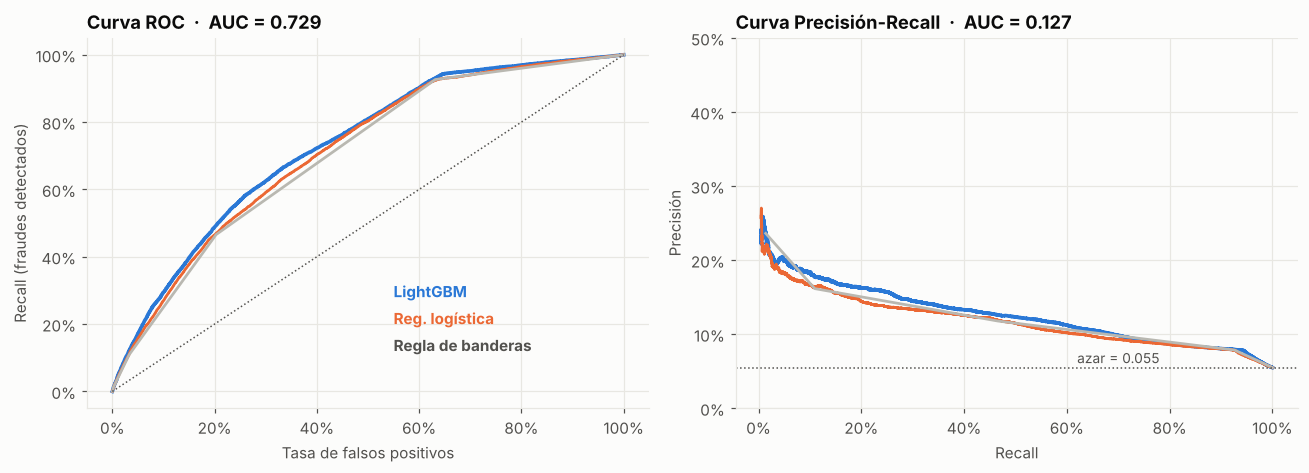

In [19]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
series = [("LightGBM", p_te, BLUE, 2.4), ("Reg. logística", p_lr, ORANGE, 1.8), ("Regla de banderas", score_reglas, GRAY, 1.8)]
for nombre, p, col, lw in series:
    fpr, tpr, _ = roc_curve(y_te, p); axes[0].plot(fpr, tpr, color=col, lw=lw)
    pr, rc, _ = precision_recall_curve(y_te, p); ok = rc[:-1] >= 0.005; axes[1].plot(rc[:-1][ok], pr[:-1][ok], color=col, lw=lw)   # se omiten los primeros puntos (recall ~0), muy ruidosos
axes[0].plot([0, 1], [0, 1], color=INK2, ls=":", lw=1)
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Recall (fraudes detectados)")
axes[0].set_title(f"Curva ROC  ·  AUC = {res_test.loc['LightGBM (final)', 'ROC-AUC']:.3f}")
axes[1].axhline(y_te.mean(), color=INK2, ls=":", lw=1)
axes[1].text(0.62, y_te.mean() + 0.006, f"azar = {y_te.mean():.3f}", color=INK2, fontsize=9)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precisión"); axes[1].set_ylim(0, 0.5)
axes[1].set_title(f"Curva Precisión-Recall  ·  AUC = {res_test.loc['LightGBM (final)', 'PR-AUC']:.3f}")
for ax in axes:
    ax.xaxis.set_major_formatter(PCT0); ax.yaxis.set_major_formatter(PCT0)
axes[0].text(0.55, 0.28, "LightGBM", color=BLUE, fontweight="bold"); axes[0].text(0.55, 0.20, "Reg. logística", color=ORANGE, fontweight="bold")
axes[0].text(0.55, 0.12, "Regla de banderas", color=INK2, fontweight="bold")
fig.tight_layout(); save_show("06_curvas_roc_pr.png")

### 5.1 ¿Las probabilidades son confiables? (calibración)

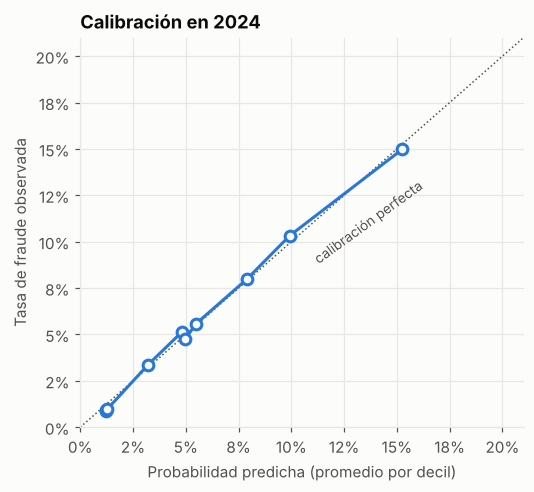

In [20]:
dec = pd.qcut(pd.Series(p_te), 10, duplicates="drop")
calib = pd.DataFrame({"pred": p_te, "real": y_te.values}).groupby(dec.values, observed=True).mean()

fig, ax = plt.subplots(figsize=(5.2, 4.6))
lim = max(calib.max().max(), 0.2) * 1.05
ax.plot([0, lim], [0, lim], color=INK2, ls=":", lw=1)
ax.plot(calib.pred, calib.real, color=BLUE, lw=2, marker="o", ms=7, mfc=SURF, mew=2)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.xaxis.set_major_formatter(PCT0); ax.yaxis.set_major_formatter(PCT0)
ax.set_xlabel("Probabilidad predicha (promedio por decil)"); ax.set_ylabel("Tasa de fraude observada")
ax.text(lim * 0.52, lim * 0.42, "calibración perfecta", color=INK2, fontsize=9, rotation=36)
ax.set_title("Calibración en 2024")
save_show("07_calibracion.png")

Los puntos siguen la diagonal: cuando el modelo dice 15 %, aproximadamente el 15 % de esas transacciones resultan fraude. Eso es lo que me permite usar la probabilidad directamente para decidir y para estimar costos, sin recalibrar.

### 5.2 Punto de operación: ¿cuántas transacciones conviene revisar?

Un banco no revisa "las que el modelo clasifica como fraude con umbral 0.5" (con una tasa base de 5.5 % casi ninguna llegaría a 50 %). Revisa **un volumen que su equipo puede absorber**. Por eso evalúo el modelo por capacidad de revisión: *si reviso el top K % de transacciones con mayor riesgo, ¿qué obtengo?*

In [21]:
def punto_operacion(y_true, p, k_pct):
    umbral = np.quantile(p, 1 - k_pct / 100)
    marca = p >= umbral
    tp = int((marca & (y_true.values == 1)).sum())
    return {"Revisar top %": k_pct, "Umbral de prob.": umbral, "Precisión": tp / marca.sum(),
            "Recall (fraudes capturados)": tp / y_true.sum(), "Lift vs azar": (tp / marca.sum()) / y_true.mean()}

KS = [1, 2, 5, 10, 15, 20, 30, 50]
tabla_op = pd.DataFrame([punto_operacion(y_te, p_te, k) for k in KS]).set_index("Revisar top %")
tabla_op.style.format({"Umbral de prob.": "{:.1%}", "Precisión": "{:.1%}", "Recall (fraudes capturados)": "{:.1%}", "Lift vs azar": "{:.2f}x"})

,Umbral de prob.,Precisión,Recall (fraudes capturados),Lift vs azar
Revisar top %,,,,
1,19.5%,19.5%,3.5%,3.54x
2,17.7%,19.1%,6.9%,3.47x
5,14.8%,16.8%,15.3%,3.06x
10,10.8%,15.0%,27.3%,2.73x
15,9.8%,13.5%,37.0%,2.47x
20,9.1%,12.6%,46.1%,2.30x
30,6.0%,11.1%,60.6%,2.02x
50,4.9%,8.7%,79.4%,1.59x


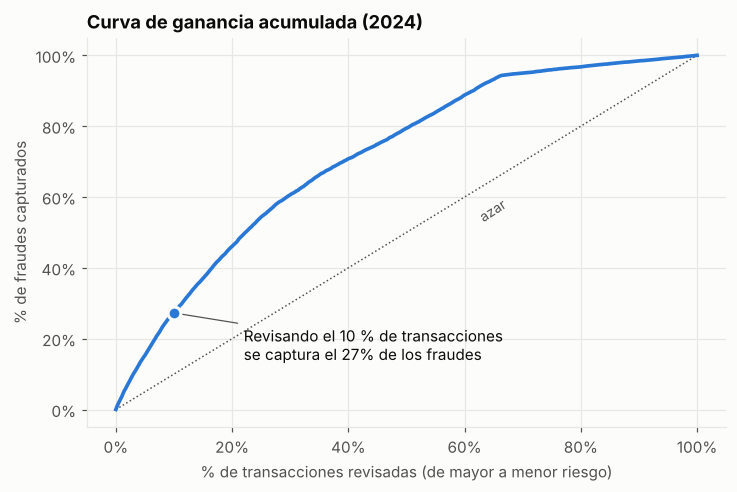

In [22]:
orden = np.argsort(-p_te)
ganancia = np.cumsum(y_te.values[orden]) / y_te.sum()
pct_rev = np.arange(1, len(p_te) + 1) / len(p_te)
paso = np.linspace(0, len(p_te) - 1, 400).astype(int)
op10 = punto_operacion(y_te, p_te, 10)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.plot([0, 1], [0, 1], color=INK2, ls=":", lw=1); ax.text(0.62, 0.53, "azar", color=INK2, fontsize=9, rotation=33)
ax.plot(pct_rev[paso], ganancia[paso], color=BLUE, lw=2.4)
ax.scatter([0.10], [op10["Recall (fraudes capturados)"]], s=70, color=BLUE, zorder=5, edgecolor=SURF, linewidth=2)
ax.annotate(f"Revisando el 10 % de transacciones\nse captura el {op10['Recall (fraudes capturados)']:.0%} de los fraudes",
            xy=(0.10, op10["Recall (fraudes capturados)"]), xytext=(0.22, 0.14), fontsize=10, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.xaxis.set_major_formatter(PCT0); ax.yaxis.set_major_formatter(PCT0)
ax.set_xlabel("% de transacciones revisadas (de mayor a menor riesgo)"); ax.set_ylabel("% de fraudes capturados")
ax.set_title("Curva de ganancia acumulada (2024)")
save_show("08_curva_ganancia.png")

### 5.3 Traducción económica

Para elegir el K óptimo hace falta un costo por revisión. No lo conozco, así que lo trato como **supuesto explícito y editable** (en la app es un control deslizante). Uso los montos reales de 2024: el beneficio de marcar una transacción fraudulenta es su monto (dinero que se evita perder), y cada alerta cuesta `R` dólares de revisión.

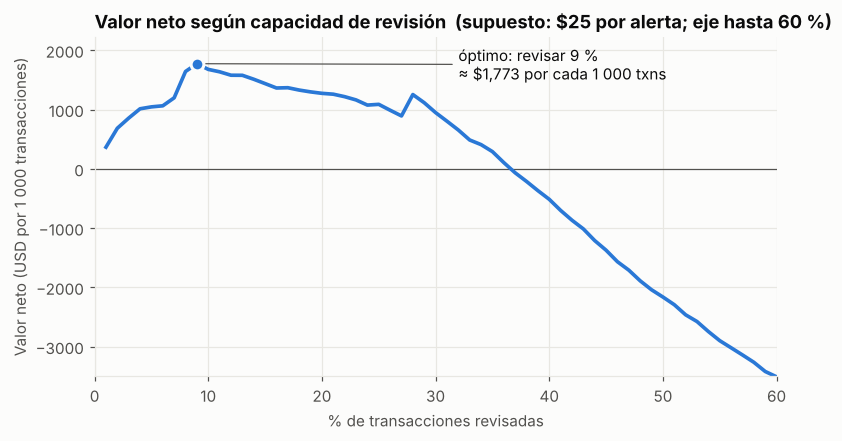

Monto medio de un fraude en 2024: $230  |  monto medio legítimo: $204
Valor neto en el punto 10 %: $1,677 por 1 000 txns


In [23]:
COSTO_REVISION = 25.0      # SUPUESTO (USD por alerta revisada). Editable en la app.
monto = X_te.log_amount.pipe(np.expm1).values
fraude = y_te.values

def valor_neto(k_pct):
    marca = p_te >= np.quantile(p_te, 1 - k_pct / 100)
    return (monto[marca & (fraude == 1)].sum() - COSTO_REVISION * marca.sum()) / len(p_te) * 1000   # por cada 1 000 txns

ks = np.arange(1, 101)
vn = np.array([valor_neto(k) for k in ks])
k_opt = int(ks[vn.argmax()])

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color=INK2, lw=0.8)
ax.plot(ks, vn, color=BLUE, lw=2.4)
ax.scatter([k_opt], [vn.max()], s=70, color=BLUE, zorder=5, edgecolor=SURF, linewidth=2)
ax.annotate(f"óptimo: revisar {k_opt} %\n≈ ${vn.max():,.0f} por cada 1 000 txns", xy=(k_opt, vn.max()),
            xytext=(32, vn.max() * 0.85), fontsize=10, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set_xlim(0, 60); ax.set_ylim(-3500, vn.max() * 1.25)
ax.set_xlabel("% de transacciones revisadas"); ax.set_ylabel("Valor neto (USD por 1 000 transacciones)")
ax.set_title(f"Valor neto según capacidad de revisión  (supuesto: ${COSTO_REVISION:.0f} por alerta; eje hasta 60 %)")
save_show("09_valor_neto.png")
print(f"Monto medio de un fraude en 2024: ${monto[fraude == 1].mean():,.0f}  |  monto medio legítimo: ${monto[fraude == 0].mean():,.0f}")
print(f"Valor neto en el punto 10 %: ${valor_neto(10):,.0f} por 1 000 txns")

El valor neto sube rápido al principio (las primeras alertas son las más rentables) y se aplana: pasado cierto punto, cada alerta adicional cuesta más de lo que evita. **El óptimo depende del costo de revisión**, que es una decisión de negocio, por eso lo dejo como parámetro en la app en lugar de esconderlo dentro del modelo. Con el supuesto de $25 el óptimo cae en torno al 9-10 %, y el valor se vuelve negativo si se revisa más de ~37 % de las transacciones. Como punto de partida operativo propongo **revisar el top 10 %**.

### 5.4 ¿Qué está aprendiendo el modelo? (explicabilidad)

Uso las contribuciones tipo SHAP que LightGBM calcula de forma nativa (`pred_contrib`): cuánto empuja cada variable la predicción hacia más o menos fraude.

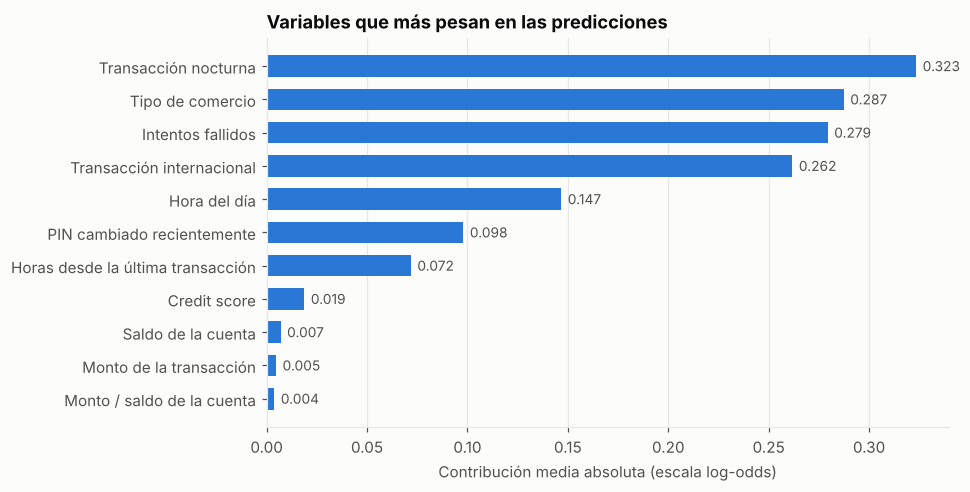

In [24]:
muestra = X_te.sample(20000, random_state=SEED)
contrib = final.booster_.predict(muestra, pred_contrib=True)        # última columna = sesgo
contrib_df = pd.DataFrame(contrib[:, :-1], columns=FEATURES, index=muestra.index)
imp = contrib_df.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh([FEATURE_LABELS[c] for c in imp.index], imp.values, color=BLUE, height=0.65)
for i, v in enumerate(imp.values):
    ax.text(v + imp.max() * 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribución media absoluta (escala log-odds)")
ax.set_title("Variables que más pesan en las predicciones")
save_show("10_importancia_variables.png")

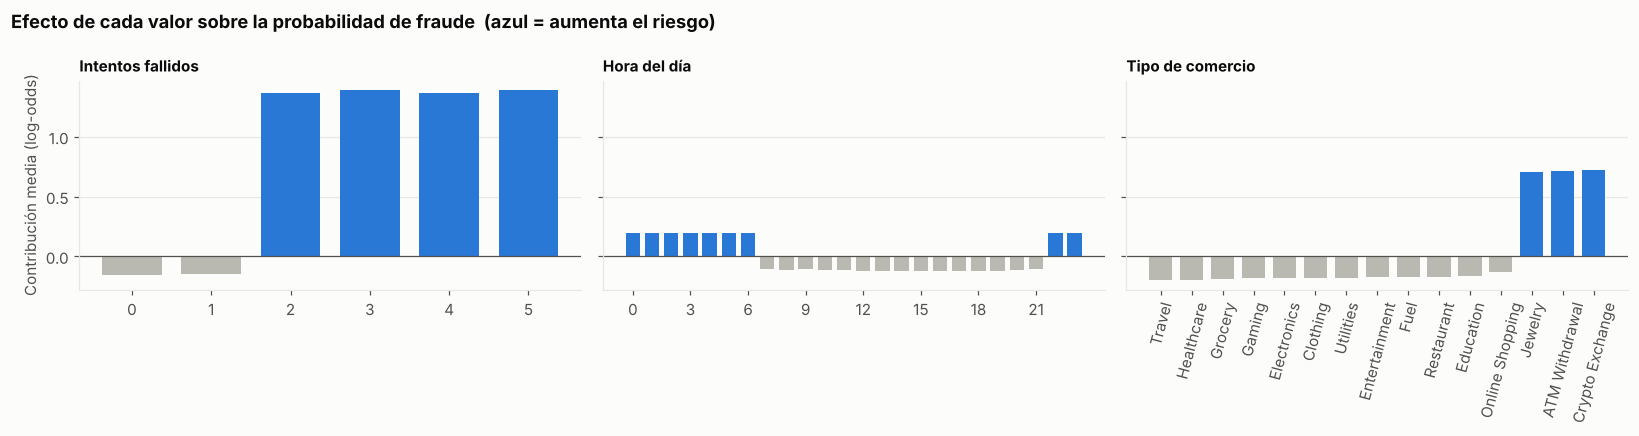

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col, tit in zip(axes, ["failed_attempts", "hour_of_day", "merchant_category"],
                        ["Intentos fallidos", "Hora del día", "Tipo de comercio"]):
    if col == "merchant_category":
        g = contrib_df[col].groupby(muestra[col].astype(str)).mean().sort_values()
        ax.bar(g.index, g.values, color=[BLUE if m in RISKY_MERCHANTS else GRAY for m in g.index], width=0.75)
        ax.tick_params(axis="x", rotation=75)
    else:
        g = contrib_df[col].groupby(muestra[col]).mean()
        ax.bar(g.index.astype(str), g.values, color=[BLUE if v > 0 else GRAY for v in g.values], width=0.75)
        if col == "hour_of_day": ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels(range(0, 24, 3))
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(tit, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Contribución media (log-odds)")
fig.suptitle("Efecto de cada valor sobre la probabilidad de fraude  (azul = aumenta el riesgo)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save_show("11_efectos_variables.png")

El modelo aprendió exactamente lo que el EDA anticipaba: el **umbral de 2 intentos fallidos**, la **franja nocturna**, y los **tres comercios de riesgo**. Que las explicaciones del modelo coincidan con la lógica de negocio es una buena señal de que no está capturando ruido.

### 5.5 Robustez: backtesting temporal

¿El rendimiento depende de haber elegido 2024 como prueba? Repito el ejercicio "entreno con el pasado, pruebo con el año siguiente" para varios años:

In [26]:
bt = []
for anio_test in [2021, 2022, 2023, 2024]:
    m = lgb.LGBMClassifier(**final_params).fit(X_all[df.anio < anio_test], y[df.anio < anio_test])
    p = m.predict_proba(X_all[df.anio == anio_test])[:, 1]
    yt = y[df.anio == anio_test]
    bt.append({"Entrena con": f"2020-{anio_test - 1}", "Prueba en": anio_test, "Tasa base": yt.mean(),
               "ROC-AUC": roc_auc_score(yt, p), "PR-AUC": average_precision_score(yt, p),
               "Recall @ top 10 %": punto_operacion(yt, p, 10)["Recall (fraudes capturados)"]})
backtest = pd.DataFrame(bt)
backtest.style.format({"Tasa base": "{:.2%}", "ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "Recall @ top 10 %": "{:.1%}"}).hide(axis="index")

Entrena con,Prueba en,Tasa base,ROC-AUC,PR-AUC,Recall @ top 10 %
2020-2020,2021,5.55%,0.7272,0.1290,27.9%
2020-2021,2022,5.52%,0.7280,0.1288,27.5%
2020-2022,2023,5.58%,0.7242,0.1277,27.1%
2020-2023,2024,5.49%,0.7289,0.1265,27.3%


El rendimiento es prácticamente idéntico en todos los años, incluso entrenando con solo un año de historia: no hay sobreajuste a un periodo ni degradación temporal.

### 5.6 Análisis de errores

¿Hay tipos de fraude o comercios que el modelo detecta peor? Miro el recall en el punto de operación (top 10 %) por `fraud_type` (la variable que dejé fuera por leakage, útil ahora solo para auditar):

In [27]:
umbral10 = np.quantile(p_te, 0.90)
aud = pd.DataFrame({"p": p_te, "fraude": y_te.values, "tipo": df.loc[es_test, "fraud_type"].values,
                    "comercio": df.loc[es_test, "merchant_category"].values})
aud["marcada"] = aud.p >= umbral10
por_tipo = aud[aud.fraude == 1].groupby("tipo").marcada.agg(["mean", "size"]).rename(columns={"mean": "Recall @ top 10 %", "size": "Fraudes"})
por_tipo.sort_values("Recall @ top 10 %", ascending=False).style.format({"Recall @ top 10 %": "{:.1%}", "Fraudes": "{:,}"})

,Recall @ top 10 %,Fraudes
tipo,,
Card Cloning,28.1%,"1,780"
Synthetic Identity,27.7%,"1,822"
Phishing,27.5%,"1,852"
Identity Theft,27.5%,"1,841"
Friendly Fraud,27.5%,"1,824"
Account Takeover,25.4%,"1,830"


El recall es parejo entre los seis tipos de fraude (25 %-28 %); la diferencia más grande, toma de cuenta con 25.4 %, cae dentro de lo esperable por azar con ~1 800 casos por tipo (±2 puntos). El modelo no tiene un punto ciego por tipo. En un dataset real esperaría diferencias importantes (clonación de tarjeta y toma de cuenta dejan huellas distintas); que aquí no aparezcan es otra señal de que los fraudes están generados con las mismas reglas, sin importar su etiqueta.

## 6. Despliegue

Dejo todo lo necesario para que la app de Streamlit funcione **sin reentrenar y sin el dataset de 150 MB**:

- `models/fraud_lgbm.txt`: el modelo en formato texto de LightGBM (portable entre versiones, a diferencia de un pickle).
- `models/metadata.json`: variables, métricas, tabla de puntos de operación, backtest e importancias.
- `data/sample_historical_2024.csv` y `data/sample_new_transactions.csv`: muestras pequeñas para probar la app.

In [28]:
from datetime import date

# 1) Modelo
final.booster_.save_model(str(MODEL_DIR / "fraud_lgbm.txt"))

# 2) Tabla de puntos de operación (1 % a 100 %) calculada sobre 2024
curva_op = []
for k in range(1, 101):
    op = punto_operacion(y_te, p_te, k)
    curva_op.append({"k_pct": k, "umbral": float(op["Umbral de prob."]), "precision": float(op["Precisión"]),
                     "recall": float(op["Recall (fraudes capturados)"]), "lift": float(op["Lift vs azar"])})

meta = {
    "modelo": "LightGBM", "version": "1.0", "fecha_entrenamiento": str(date.today()),
    "entrenado_con": "2020-01-01 a 2023-12-31", "evaluado_en": "2024", "n_entrenamiento": int(es_fit.sum()), "n_prueba": int(es_test.sum()),
    "tasa_base_prueba": float(y_te.mean()), "k_recomendado_pct": 10,
    "monto_medio_fraude": float(monto[fraude == 1].mean()),
    "hiperparametros": {k: (float(v) if isinstance(v, float) else int(v) if isinstance(v, (int, np.integer)) else v)
                        for k, v in final_params.items() if k in ("num_leaves", "min_child_samples", "colsample_bytree", "reg_lambda", "learning_rate", "n_estimators")},
    "metricas_prueba": {k: float(v) for k, v in res_test.loc["LightGBM (final)"].items()},
    "metricas_regresion_logistica": {k: float(v) for k, v in res_test.loc["Regresión logística"].items()},
    "variables": FEATURES, "etiquetas_variables": FEATURE_LABELS, "categorias_comercio": MERCHANT_CATEGORIES,
    "comercios_riesgo": RISKY_MERCHANTS,
    "puntos_operacion": curva_op,
    "importancia": [{"variable": c, "etiqueta": FEATURE_LABELS[c], "valor": float(v)} for c, v in imp.sort_values(ascending=False).items()],
    "backtest": [{"entrena": r["Entrena con"], "prueba": int(r["Prueba en"]), "pr_auc": float(r["PR-AUC"]), "roc_auc": float(r["ROC-AUC"]),
                  "recall_top10": float(r["Recall @ top 10 %"]), "tasa_base": float(r["Tasa base"])} for _, r in backtest.iterrows()],
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1), encoding="utf-8")

# 3) Muestras para la app (solo columnas necesarias)
cols_app = ["transaction_id", "transaction_date", "transaction_time", "merchant_category", "transaction_amount",
            "account_balance", "credit_score", "time_since_last_txn_hrs", "failed_attempts", "is_international",
            "pin_changed_recently"]
test_df = df[es_test]
hist = test_df.sample(3000, random_state=SEED)
nuevas = test_df.drop(hist.index).sample(1000, random_state=SEED)
hist[cols_app + ["is_fraud"]].to_csv(DATA_DIR / "sample_historical_2024.csv", index=False)
nuevas[cols_app].to_csv(DATA_DIR / "sample_new_transactions.csv", index=False)

# 4) Verificación: el modelo guardado, cargado desde cero, da exactamente las mismas probabilidades
cargado = lgb.Booster(model_file=str(MODEL_DIR / "fraud_lgbm.txt"))
dif = np.abs(cargado.predict(X_te) - p_te).max()
print(f"Diferencia máxima entre modelo en memoria y modelo cargado: {dif:.2e}")
print(f"Tamaño del modelo: {(MODEL_DIR / 'fraud_lgbm.txt').stat().st_size / 1024:.0f} KB")
assert dif < 1e-9

Diferencia máxima entre modelo en memoria y modelo cargado: 0.00e+00
Tamaño del modelo: 152 KB


## 7. Conclusiones, limitaciones y próximos pasos

### Resultados (evaluados en 2024, datos que el modelo nunca vio)

| Métrica | LightGBM | Reg. logística | Regla de banderas | Azar |
|---|---|---|---|---|
| ROC-AUC | **0.729** | 0.715 | 0.704 | 0.500 |
| PR-AUC | **0.127** | 0.118 | 0.101 | 0.055 |

- **Operativo:** revisando el **10 %** de transacciones con mayor riesgo se captura el **27 %** de los fraudes (2.7 veces mejor que el azar); con el 20 % se llega al 46 %.
- **Calibración:** las probabilidades son confiables, así que sirven para decidir umbrales y estimar costos.
- **Estabilidad:** el rendimiento es el mismo en los cuatro años del backtesting.

### Lectura honesta

El modelo mejora a las líneas base, pero por un margen **moderado**: la señal del dataset está concentrada en cinco banderas de riesgo, y una regla que las cuenta ya alcanza un ROC-AUC de 0.70. Ningún algoritmo, ajuste de hiperparámetros o conjunto de variables que probé pasó de ~0.73. Interpreto ese valor como el **límite de información** de estos datos (el resto parece ruido aleatorio del generador), no como un problema del modelado. En un dataset real esperaría más señal y diferencias entre algoritmos más grandes.

### Lo que aprendí en el proceso

1. **Fuga de información:** `fraud_type` solo existe cuando hay fraude. Usarla habría dado métricas casi perfectas y completamente falsas.
2. **Balancear clases no siempre ayuda:** en este caso empeoró la calibración sin mejorar el ranking.
3. **Partición temporal** en lugar de aleatoria: reproduce cómo se usaría el modelo en producción.
4. **Menos variables, mismo rendimiento:** 11 variables igualan a 20 y simplifican la operación.
5. **Probar hipótesis y descartarlas** (historial del cliente, ciudad, país) también es resultado.

### Limitaciones

- El dataset es **sintético**: la ciudad no coincide con el país del cliente y los seis tipos de fraude se comportan igual.
- El modelo puntúa transacciones; no pronostica el volumen futuro de fraude. La tasa fue estable en los 5 años.
- El costo de revisión ($25) es un supuesto; el óptimo operativo depende de él.
- No hay datos de dispositivo, geolocalización ni secuencias de comportamiento por cliente, que en la práctica suelen ser las señales más fuertes.

### Próximos pasos

- Probar el enfoque sobre datos reales, o sobre un dataset con más estructura (historial por cliente, comportamiento reciente).
- Decisión sensible al monto: alertar cuando `probabilidad × monto` supere el costo de revisión, en vez de un umbral único.
- Monitoreo de deriva de datos y reentrenamiento periódico.
- Exponer el modelo como API (por ejemplo, FastAPI) para integrarlo con un flujo de transacciones en línea.